# Baseline YOLOv10-S - dataset pills-sxdht

Fine-tuning de yolov10s.pt (preentrenado en COCO) dejando los parámetros por defecto de ultralytics.

En Colab: Entorno de ejecución -> Cambiar tipo de entorno -> GPU T4

In [1]:
!pip install -q ultralytics datasets

In [2]:
from pathlib import Path
import cv2
from datasets import load_dataset
from ultralytics import YOLO
from IPython.display import Image, display

SEED = 0
DATA_DIR = Path("data/pills_yolo")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Cargar dataset

In [3]:
ds = load_dataset("Francesco/pills-sxdht")

# nombres de las clases (cambia segun la version de datasets)
objs = ds["train"].features["objects"]
if hasattr(objs, "feature"):
    clases = objs.feature["category"].names  # datasets 3.x
else:
    clases = objs["category"].feature.names  # datasets 4.x (colab)

print(ds)
print(clases)

README.md:   0%|          | 0.00/3.51k [00:00<?, ?B/s]

data/train-00000-of-00001-d15b632ebb4ea5(…): reconstructing file:   0%|          |  0.00B / 17.1MB            

data/train-00000-of-00001-d15b632ebb4ea5(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-d6f6f66b7(…): reconstructing file:   0%|          |  0.00B / 2.64MB            

data/validation-00000-of-00001-d6f6f66b7(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-1afd43b66cacbc9(…): reconstructing file:   0%|          |  0.00B / 4.87MB            

data/test-00000-of-00001-1afd43b66cacbc9(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 316
    })
    validation: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 45
    })
    test: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 90
    })
})
['pills', 'Cipro 500', 'Ibuphil 600 mg', 'Ibuphil Cold 400-60', 'Xyzall 5mg', 'blue', 'pink', 'red', 'white']


## Pasar a formato YOLO

Las bbox vienen en formato COCO (x, y, w, h en pixeles) y YOLO quiere un txt por imagen con `clase cx cy w h` normalizado.

Dejamos las 9 clases como vienen (la clase 0 'pills' no tiene ninguna anotacion).

In [4]:
splits = {"train": "train", "validation": "val", "test": "test"}

for split_hf, split_yolo in splits.items():
    (DATA_DIR / "images" / split_yolo).mkdir(parents=True, exist_ok=True)
    (DATA_DIR / "labels" / split_yolo).mkdir(parents=True, exist_ok=True)

    for ej in ds[split_hf]:
        nombre = str(ej["image_id"])
        ej["image"].convert("RGB").save(DATA_DIR / "images" / split_yolo / (nombre + ".jpg"))

        W, H = ej["width"], ej["height"]
        lineas = []
        for (x, y, w, h), c in zip(ej["objects"]["bbox"], ej["objects"]["category"]):
            cx = (x + w / 2) / W
            cy = (y + h / 2) / H
            lineas.append(f"{c} {cx} {cy} {w / W} {h / H}")
        with open(DATA_DIR / "labels" / split_yolo / (nombre + ".txt"), "w") as f:
            f.write("\n".join(lineas))

    print(split_hf, len(ds[split_hf]))

# yaml del dataset
with open(DATA_DIR / "data.yaml", "w") as f:
    f.write(f"path: {DATA_DIR.resolve().as_posix()}\n")
    f.write("train: images/train\nval: images/val\ntest: images/test\n")
    f.write("names:\n")
    for i, n in enumerate(clases):
        f.write(f"  {i}: '{n}'\n")

print(open(DATA_DIR / "data.yaml").read())

train 316
validation 45
test 90
path: /content/data/pills_yolo
train: images/train
val: images/val
test: images/test
names:
  0: 'pills'
  1: 'Cipro 500'
  2: 'Ibuphil 600 mg'
  3: 'Ibuphil Cold 400-60'
  4: 'Xyzall 5mg'
  5: 'blue'
  6: 'pink'
  7: 'red'
  8: 'white'



## Entrenamiento

Todo por defecto (100 epocas, imgsz 640, batch 16, optimizer auto...). Solo fijamos la semilla. Usa val para quedarse con el mejor modelo (best.pt).

In [5]:
model = YOLO("yolov10s.pt")
model.train(data=str(DATA_DIR / "data.yaml"), seed=SEED, name="yolov10s_baseline")

carpeta = Path(model.trainer.save_dir)  # runs/detect/yolov10s_baseline...
print(carpeta)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/pills_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov10s_baseline, nbs=64, nms=None, opset=None, optimize=Fal

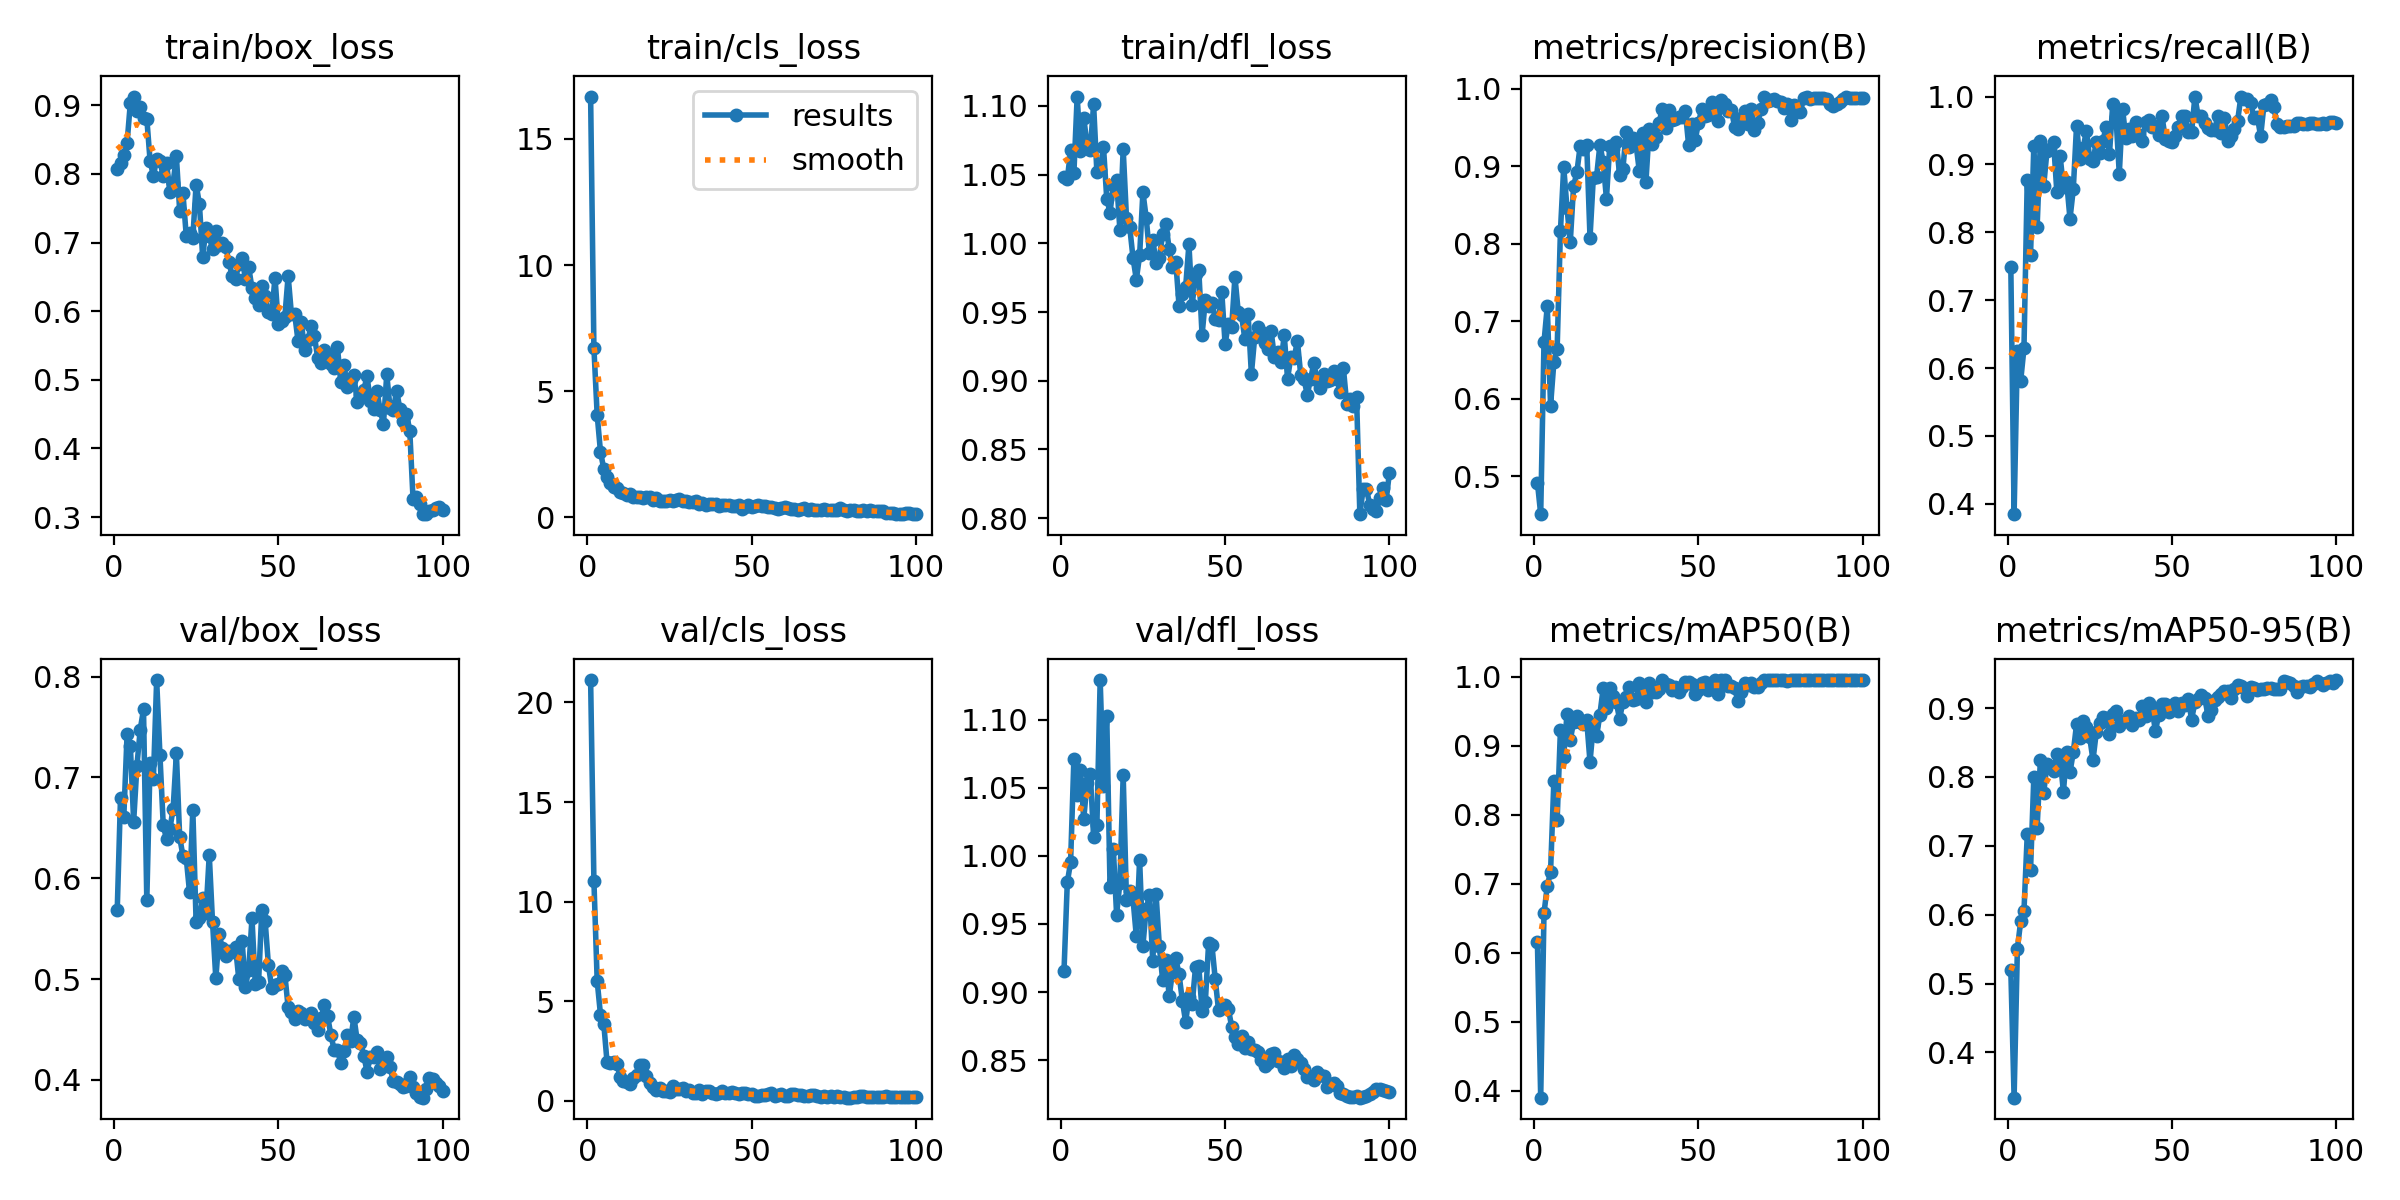

In [6]:
# curvas de loss y mAP en val
display(Image(filename=carpeta / "results.png", width=900))

## Evaluacion en test

In [7]:
best = YOLO(carpeta / "weights" / "best.pt")
metrics = best.val(data=str(DATA_DIR / "data.yaml"), split="test", name="yolov10s_baseline_test")

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("precision:", metrics.box.mp, "recall:", metrics.box.mr)
print("tiempos (ms por imagen):", metrics.speed)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s summary (fused): 103 layers, 7,221,483 parameters, 0 gradients, 21.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 27.0±12.6 MB/s, size: 73.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/data/pills_yolo/labels/test... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 486.7it/s 0.2s
val: New cache created: /content/data/pills_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.2it/s 2.7s
                   all         90         98      0.976      0.844      0.899      0.817
             Cipro 500         24         26      0.948      0.923      0.923      0.877
        Ibuphil 600 mg          1          1          1          0      0.332      0.265
   Ibu

In [8]:
# AP por clase
for i, c in enumerate(metrics.box.ap_class_index):
    print(clases[c], "AP50 =", round(metrics.box.ap50[i], 3), " AP50-95 =", round(metrics.box.ap[i], 3))

Cipro 500 AP50 = 0.923  AP50-95 = 0.877
Ibuphil 600 mg AP50 = 0.332  AP50-95 = 0.265
Ibuphil Cold 400-60 AP50 = 0.986  AP50-95 = 0.964
Xyzall 5mg AP50 = 0.972  AP50-95 = 0.806
blue AP50 = 0.995  AP50-95 = 0.912
pink AP50 = 0.995  AP50-95 = 0.937
red AP50 = 0.995  AP50-95 = 0.9
white AP50 = 0.995  AP50-95 = 0.875


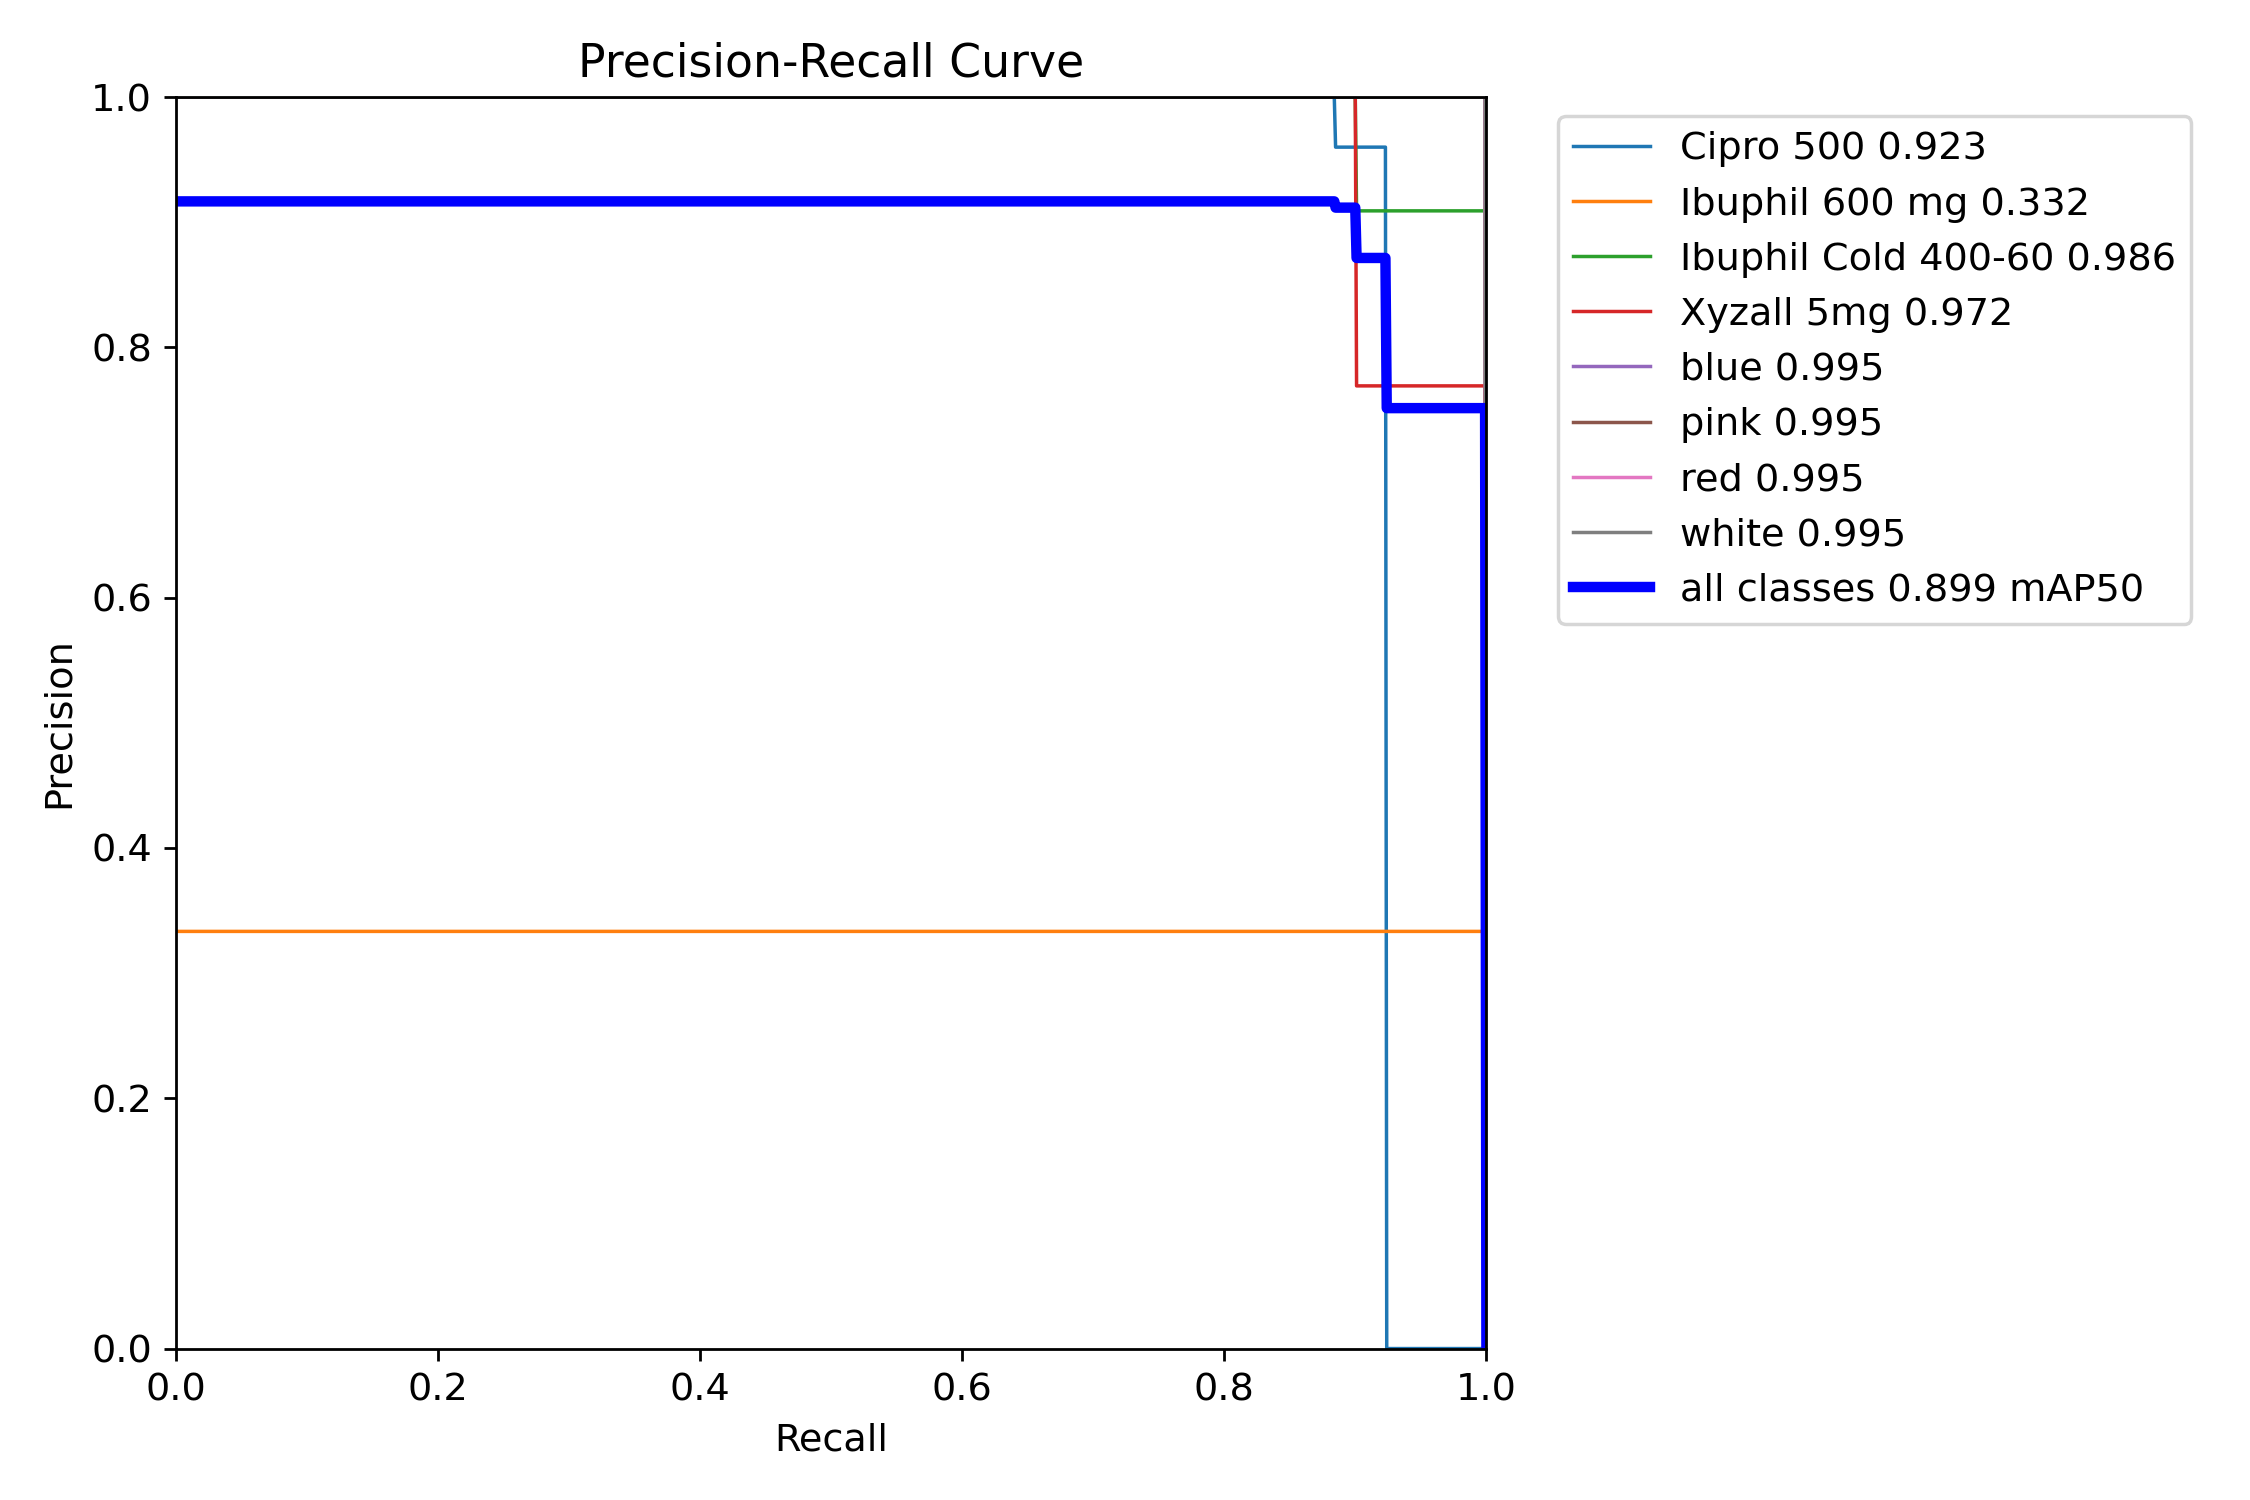

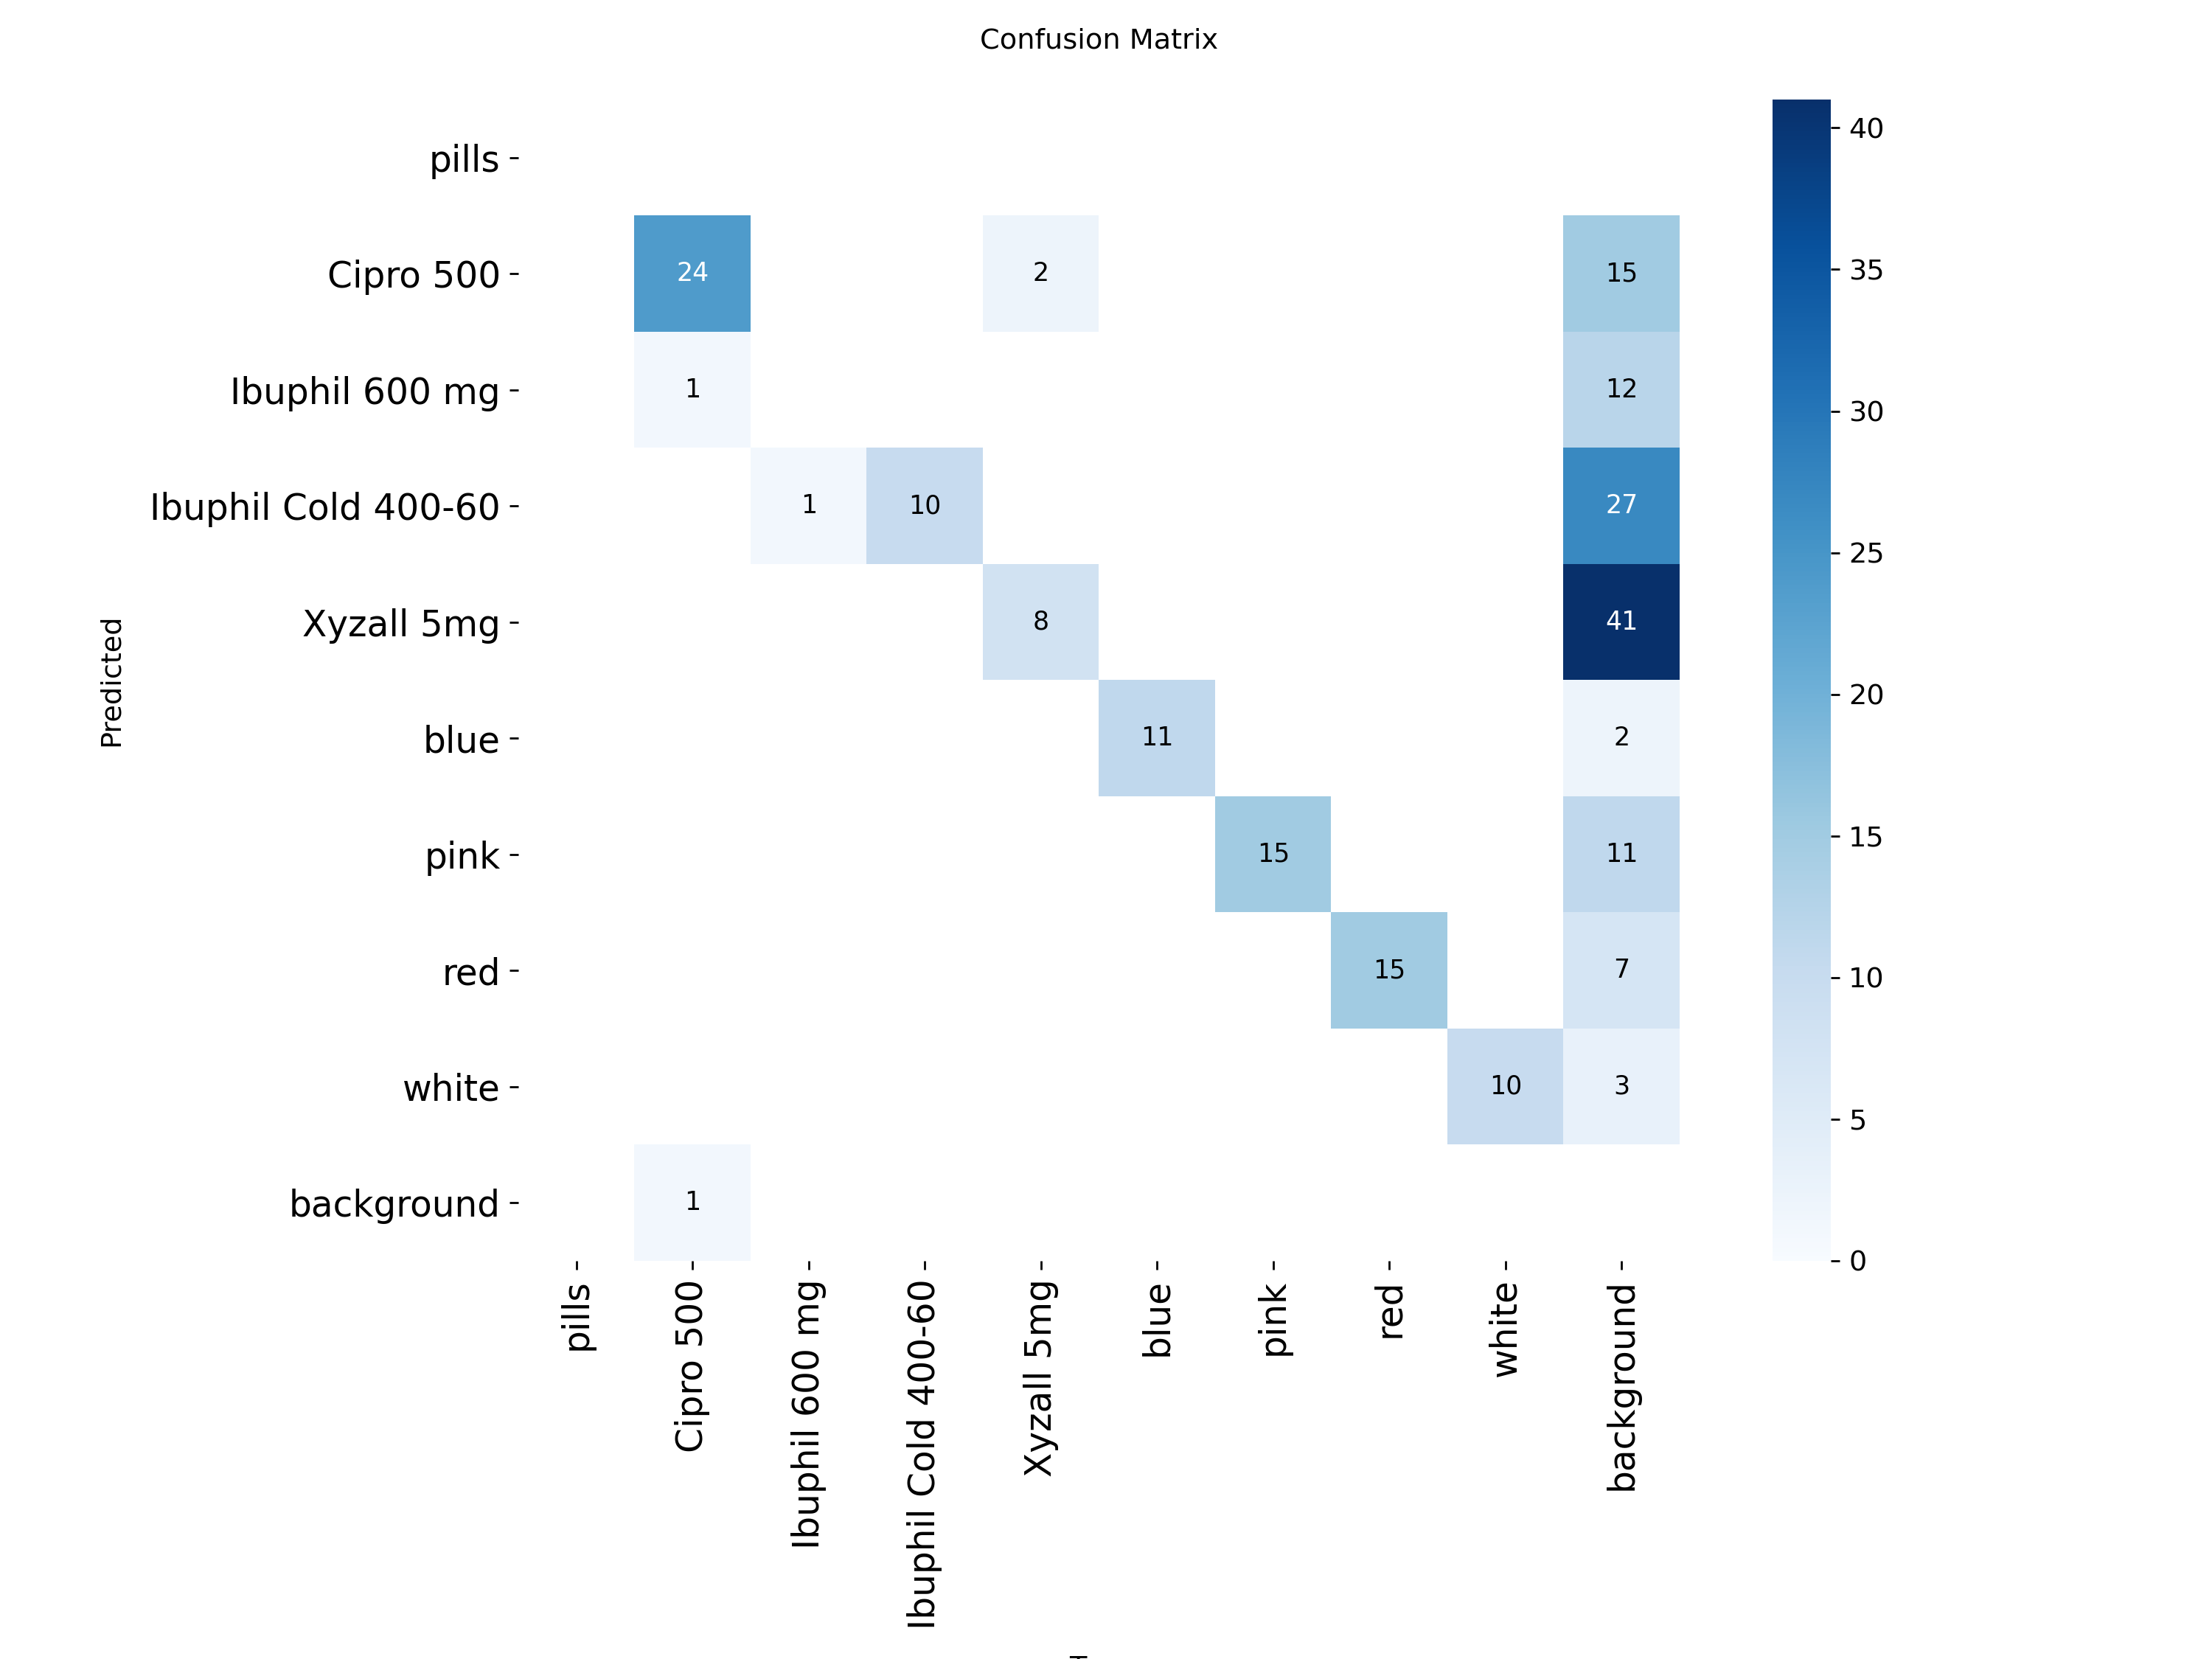

In [9]:
# curva PR y matriz de confusion (las guarda ultralytics)
display(Image(filename=Path(metrics.save_dir) / "BoxPR_curve.png", width=700))
display(Image(filename=Path(metrics.save_dir) / "confusion_matrix.png", width=700))

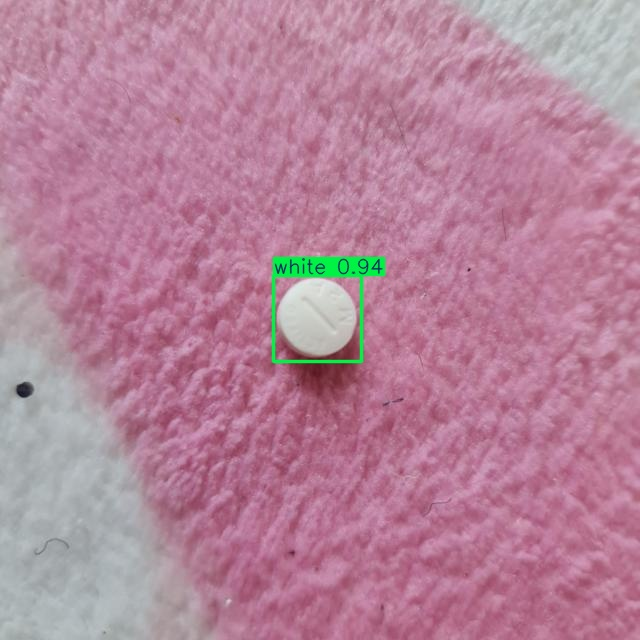

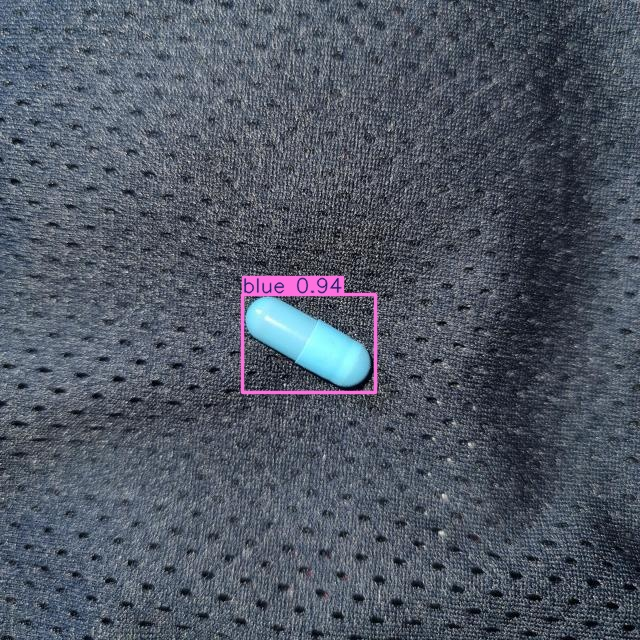

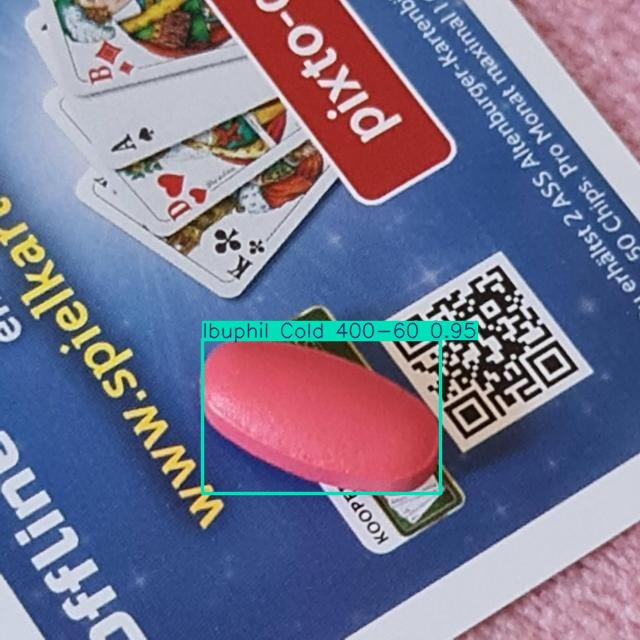

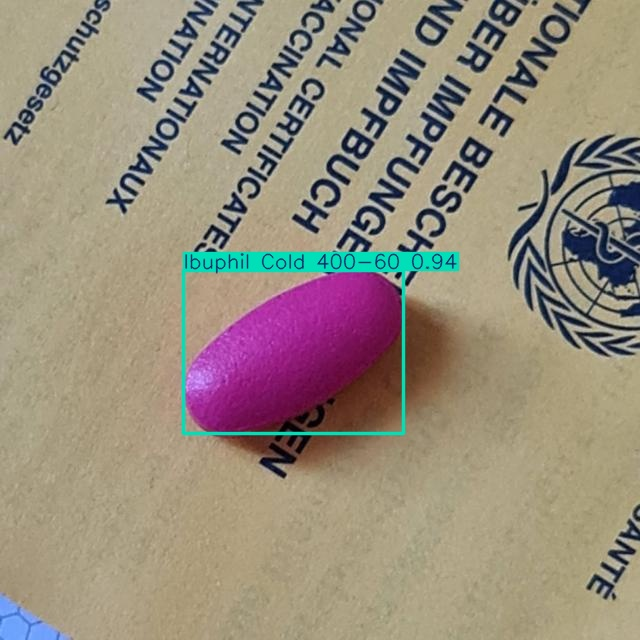

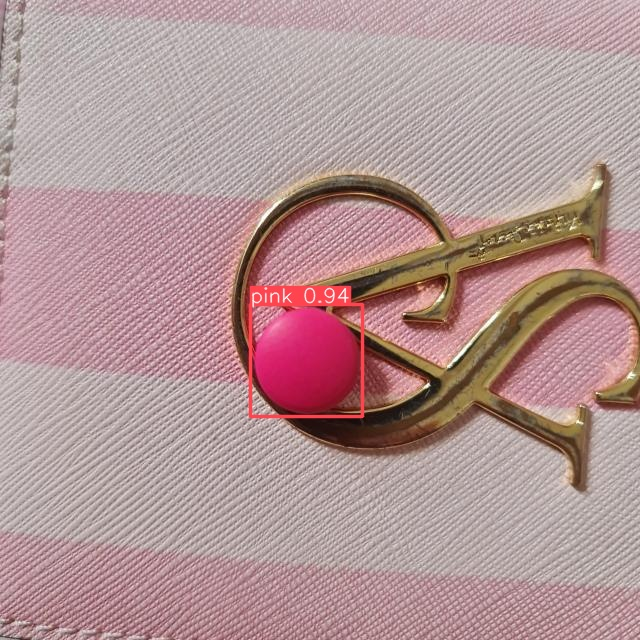

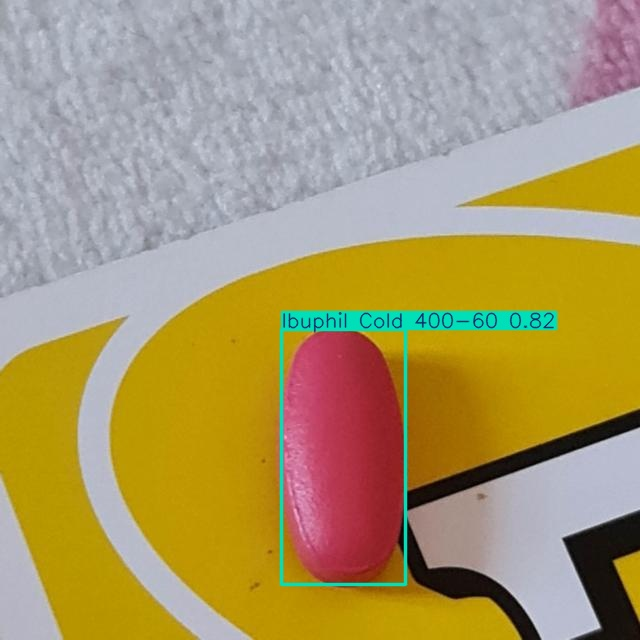

In [10]:
# algunas predicciones en test
imgs = sorted((DATA_DIR / "images" / "test").glob("*.jpg"))[:6]
for r in best.predict(imgs, verbose=False):
    display(Image(data=cv2.imencode(".jpg", r.plot())[1].tobytes(), width=400))